In [20]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

The pyspecdata.ipy extension is already loaded. To reload it, use:
  %reload_ext pyspecdata.ipy


First, we load our files, and just see what the data looks like

In [21]:
d1 = find_file("240612_TS_C10_W20_11mM_run5.DSC", exp_type="francklab_esr/romana") #cooling low conc in dodecane
d2 = find_file("240510_TS_C10_W20_run1.DSC", exp_type="francklab_esr/romana") #heating subsequently high conc in dodecane

In [22]:
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [23]:
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [24]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [25]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

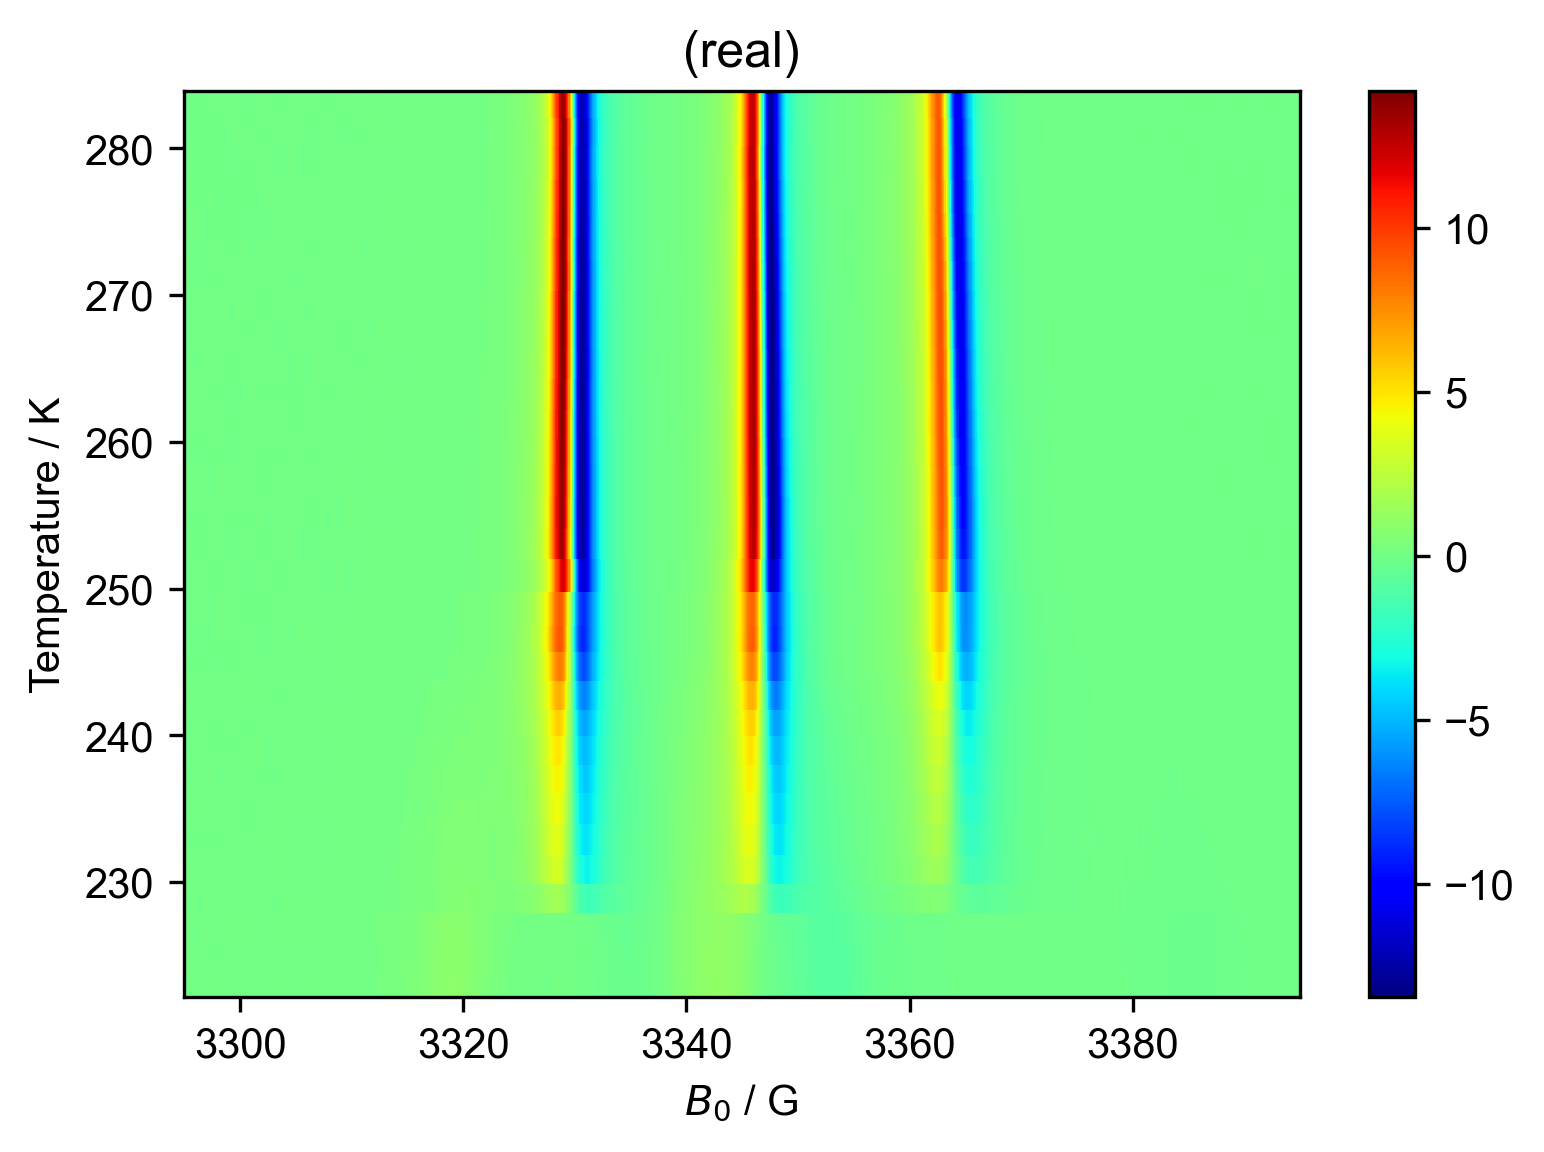

In [26]:
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1.sort('Temperature')
d1.reorder("Temperature").pcolor()
#title("TEMPO-SO$_4$ w$_0= 20$ in isooctane for cooling")

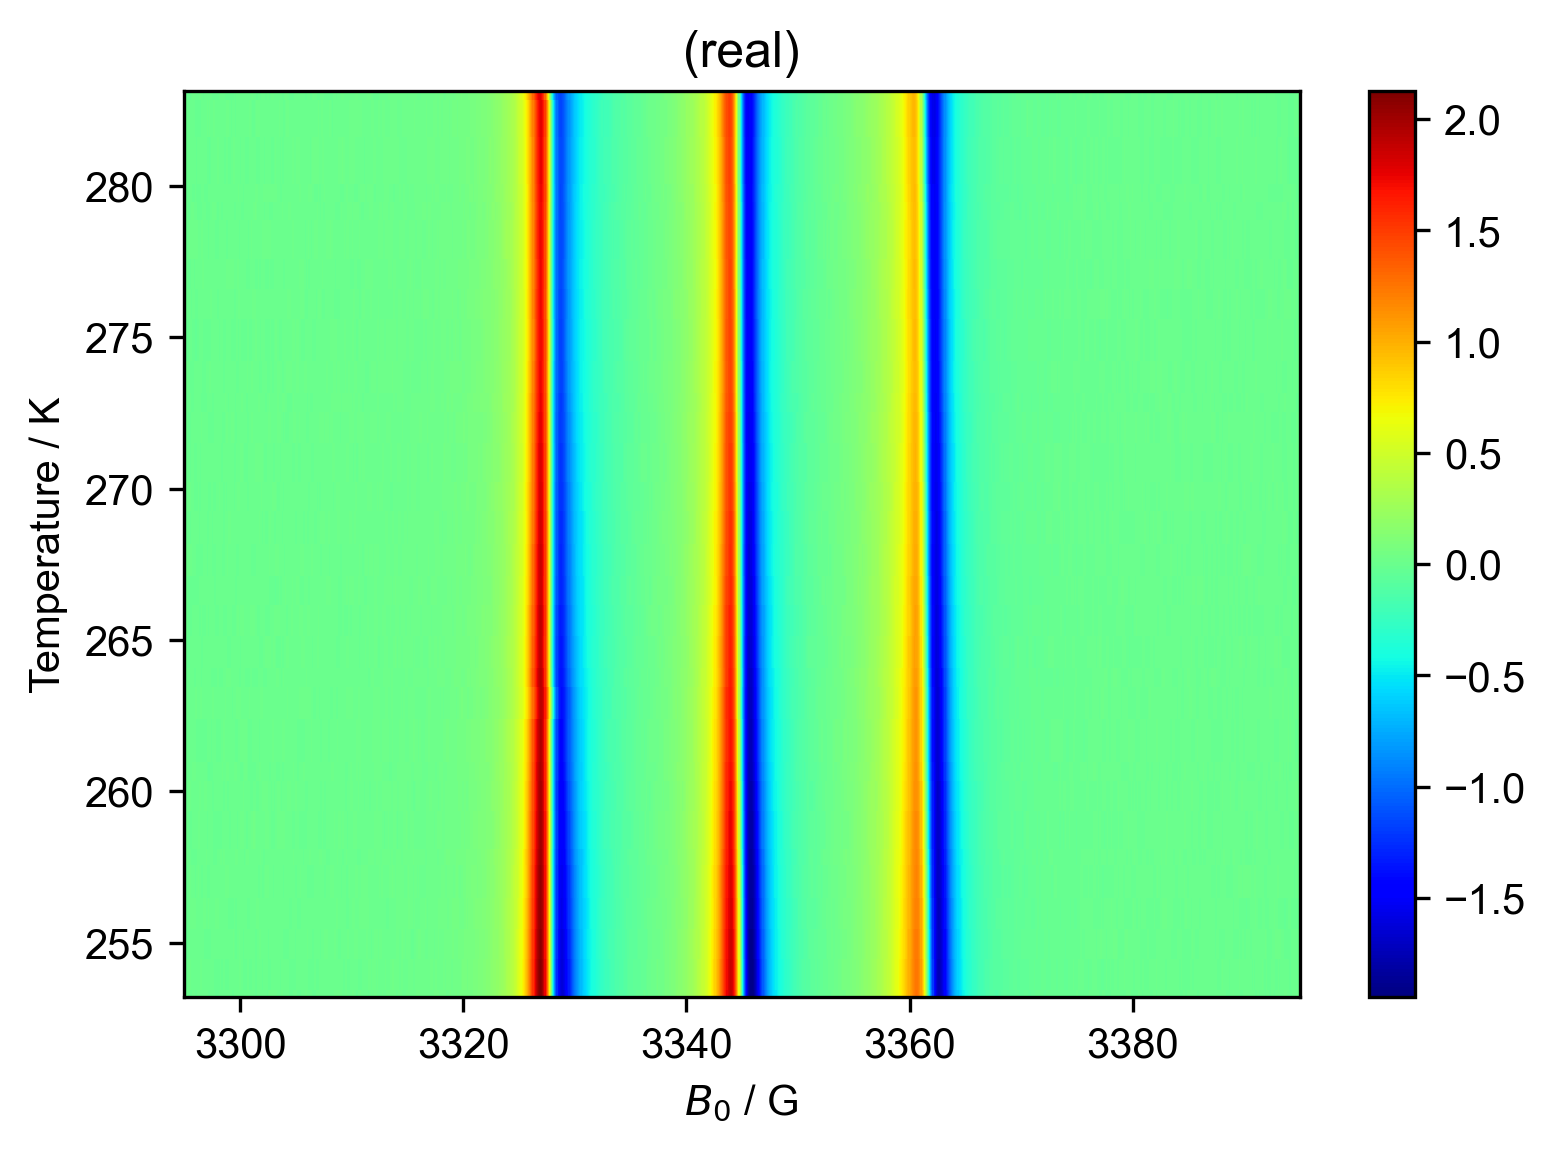

In [27]:
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]
d2.sort('Temperature')
d2.reorder("Temperature").pcolor()
#title("TEMPO-SO$_4$ w$_0= 20$ in isooctane for heating")

From this, I learn that
it's easiest to show the 1D plots above and below the transition

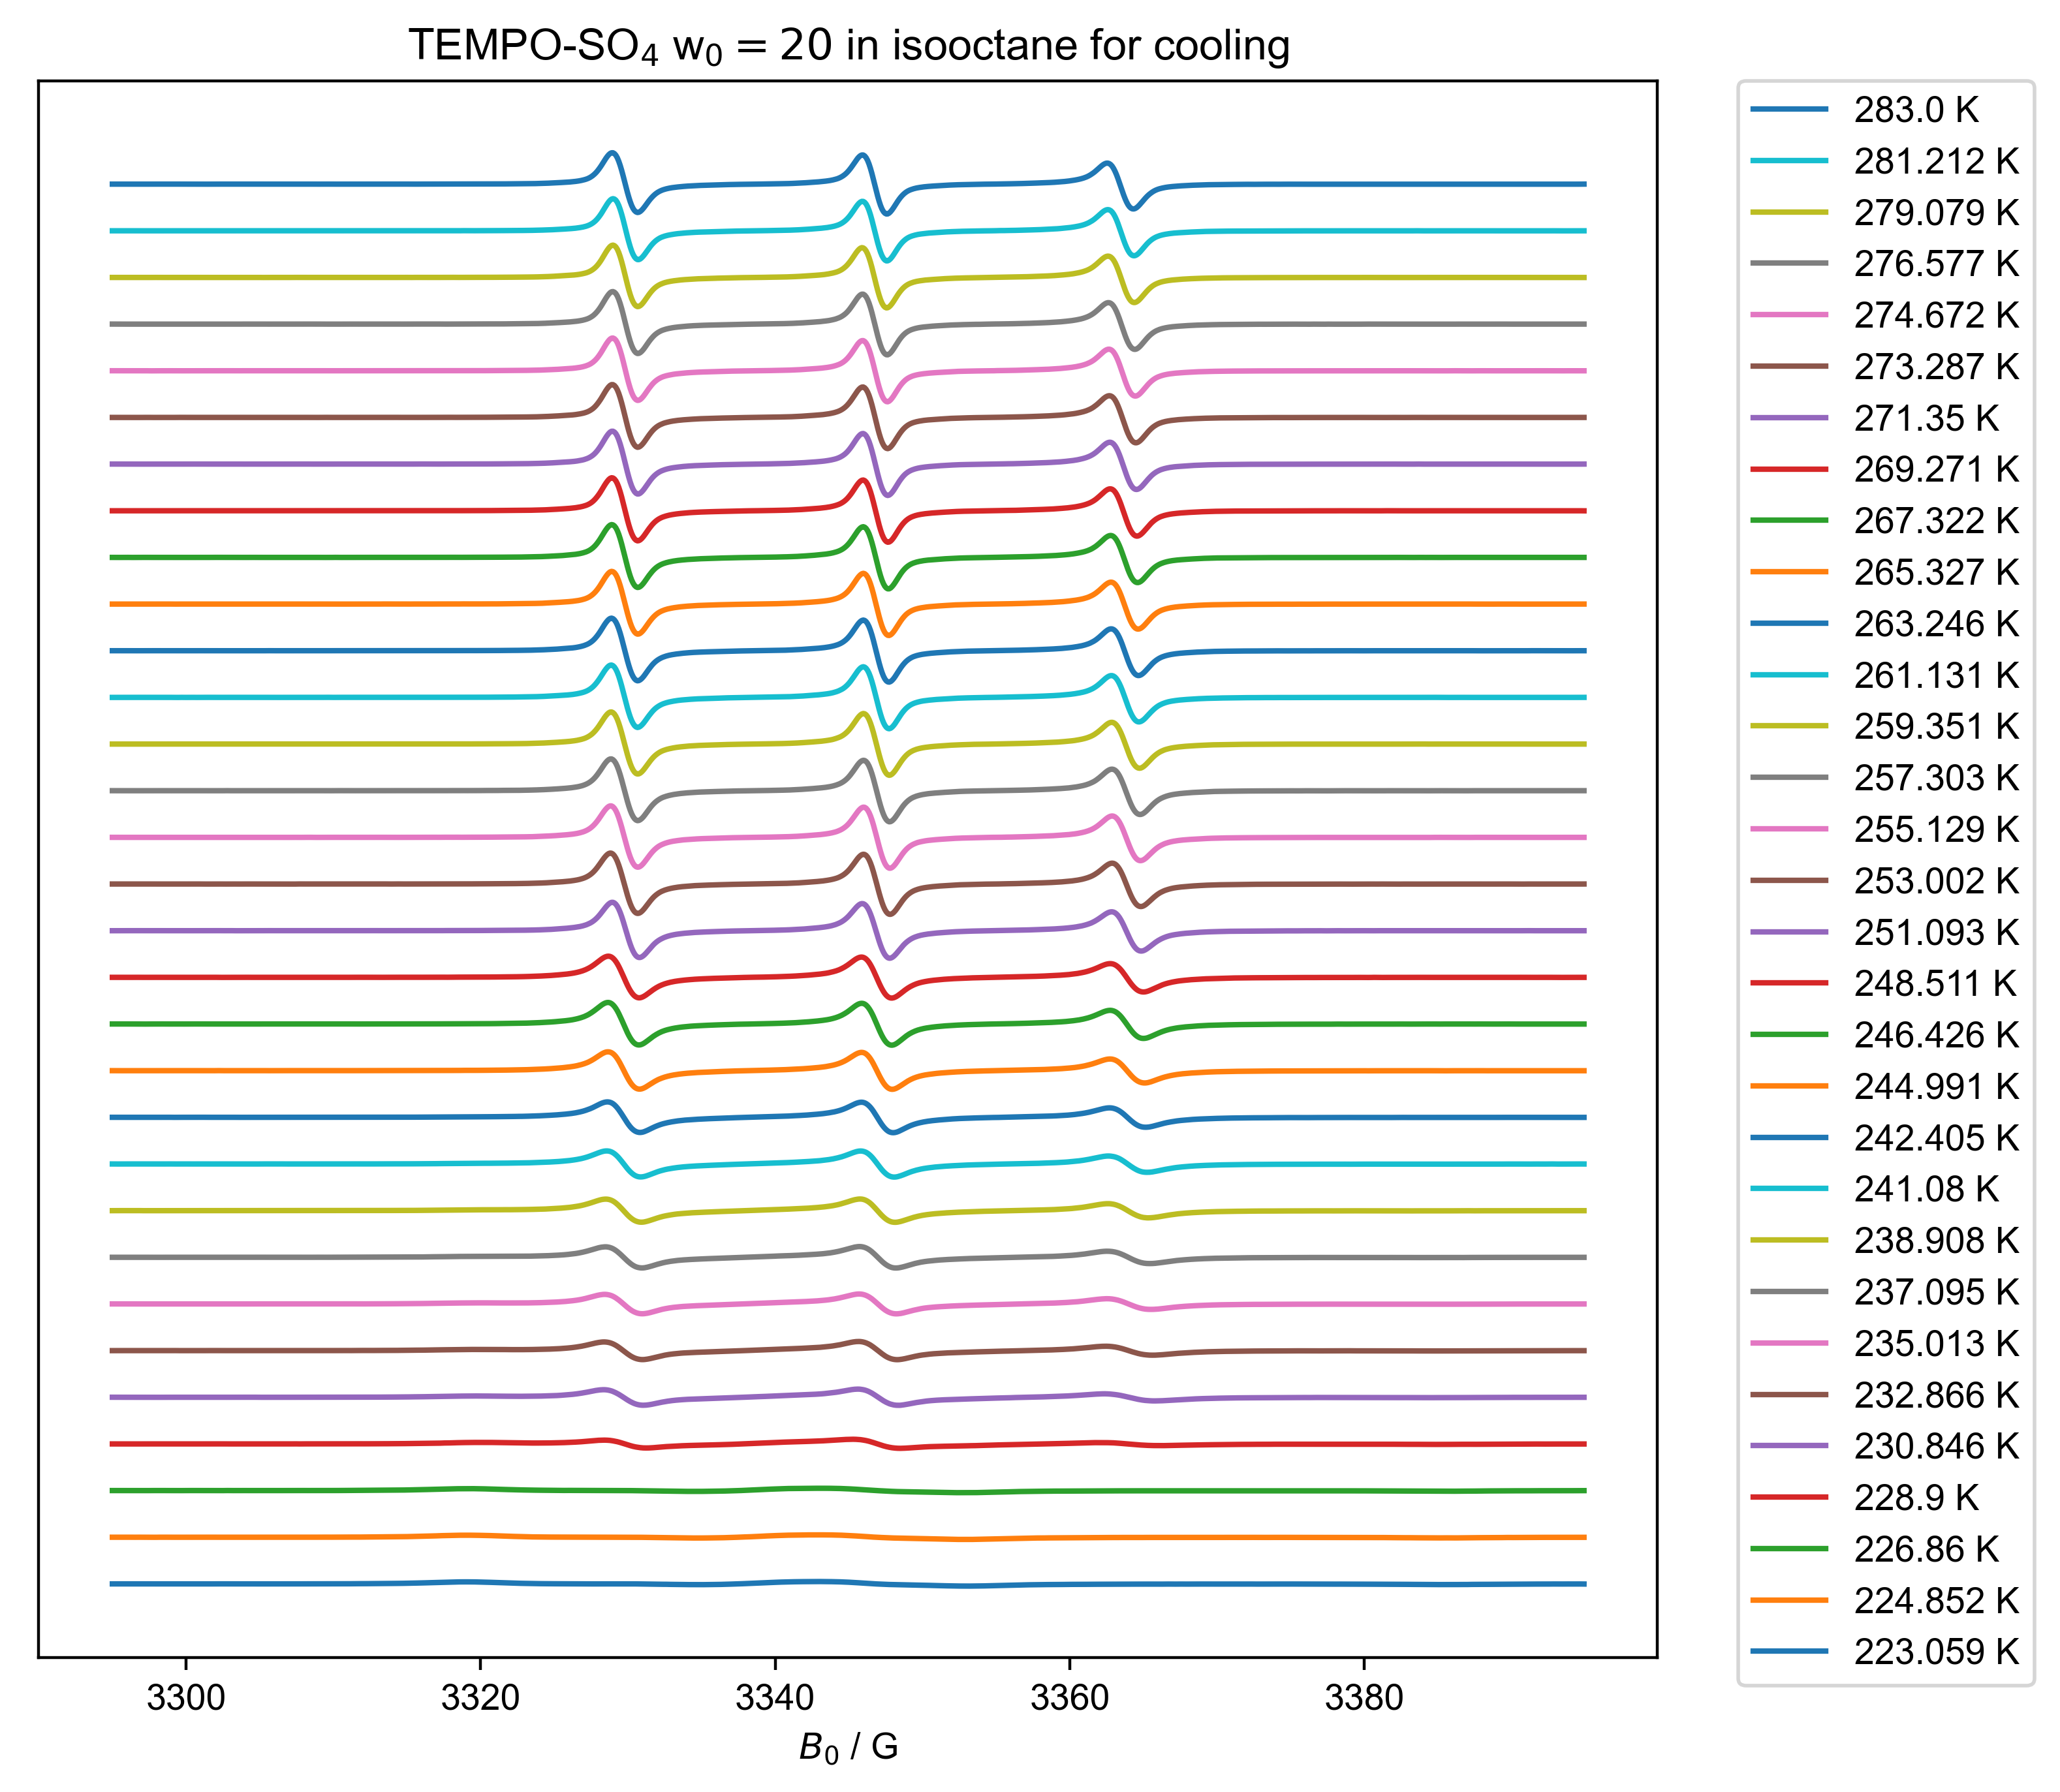

In [28]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0= 20$ in isooctane for cooling", (173, 373))
 ]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=400, figsize=(8,8)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += 20
#         offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        # Get handles and labels
        handles, labels = plt.gca().get_legend_handles_labels()
        # Reverse the order of handles and labels
        handles.reverse()
        labels.reverse()
        # Create the legend with reversed order and place it outside of the plot
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
#     fancy_legend()

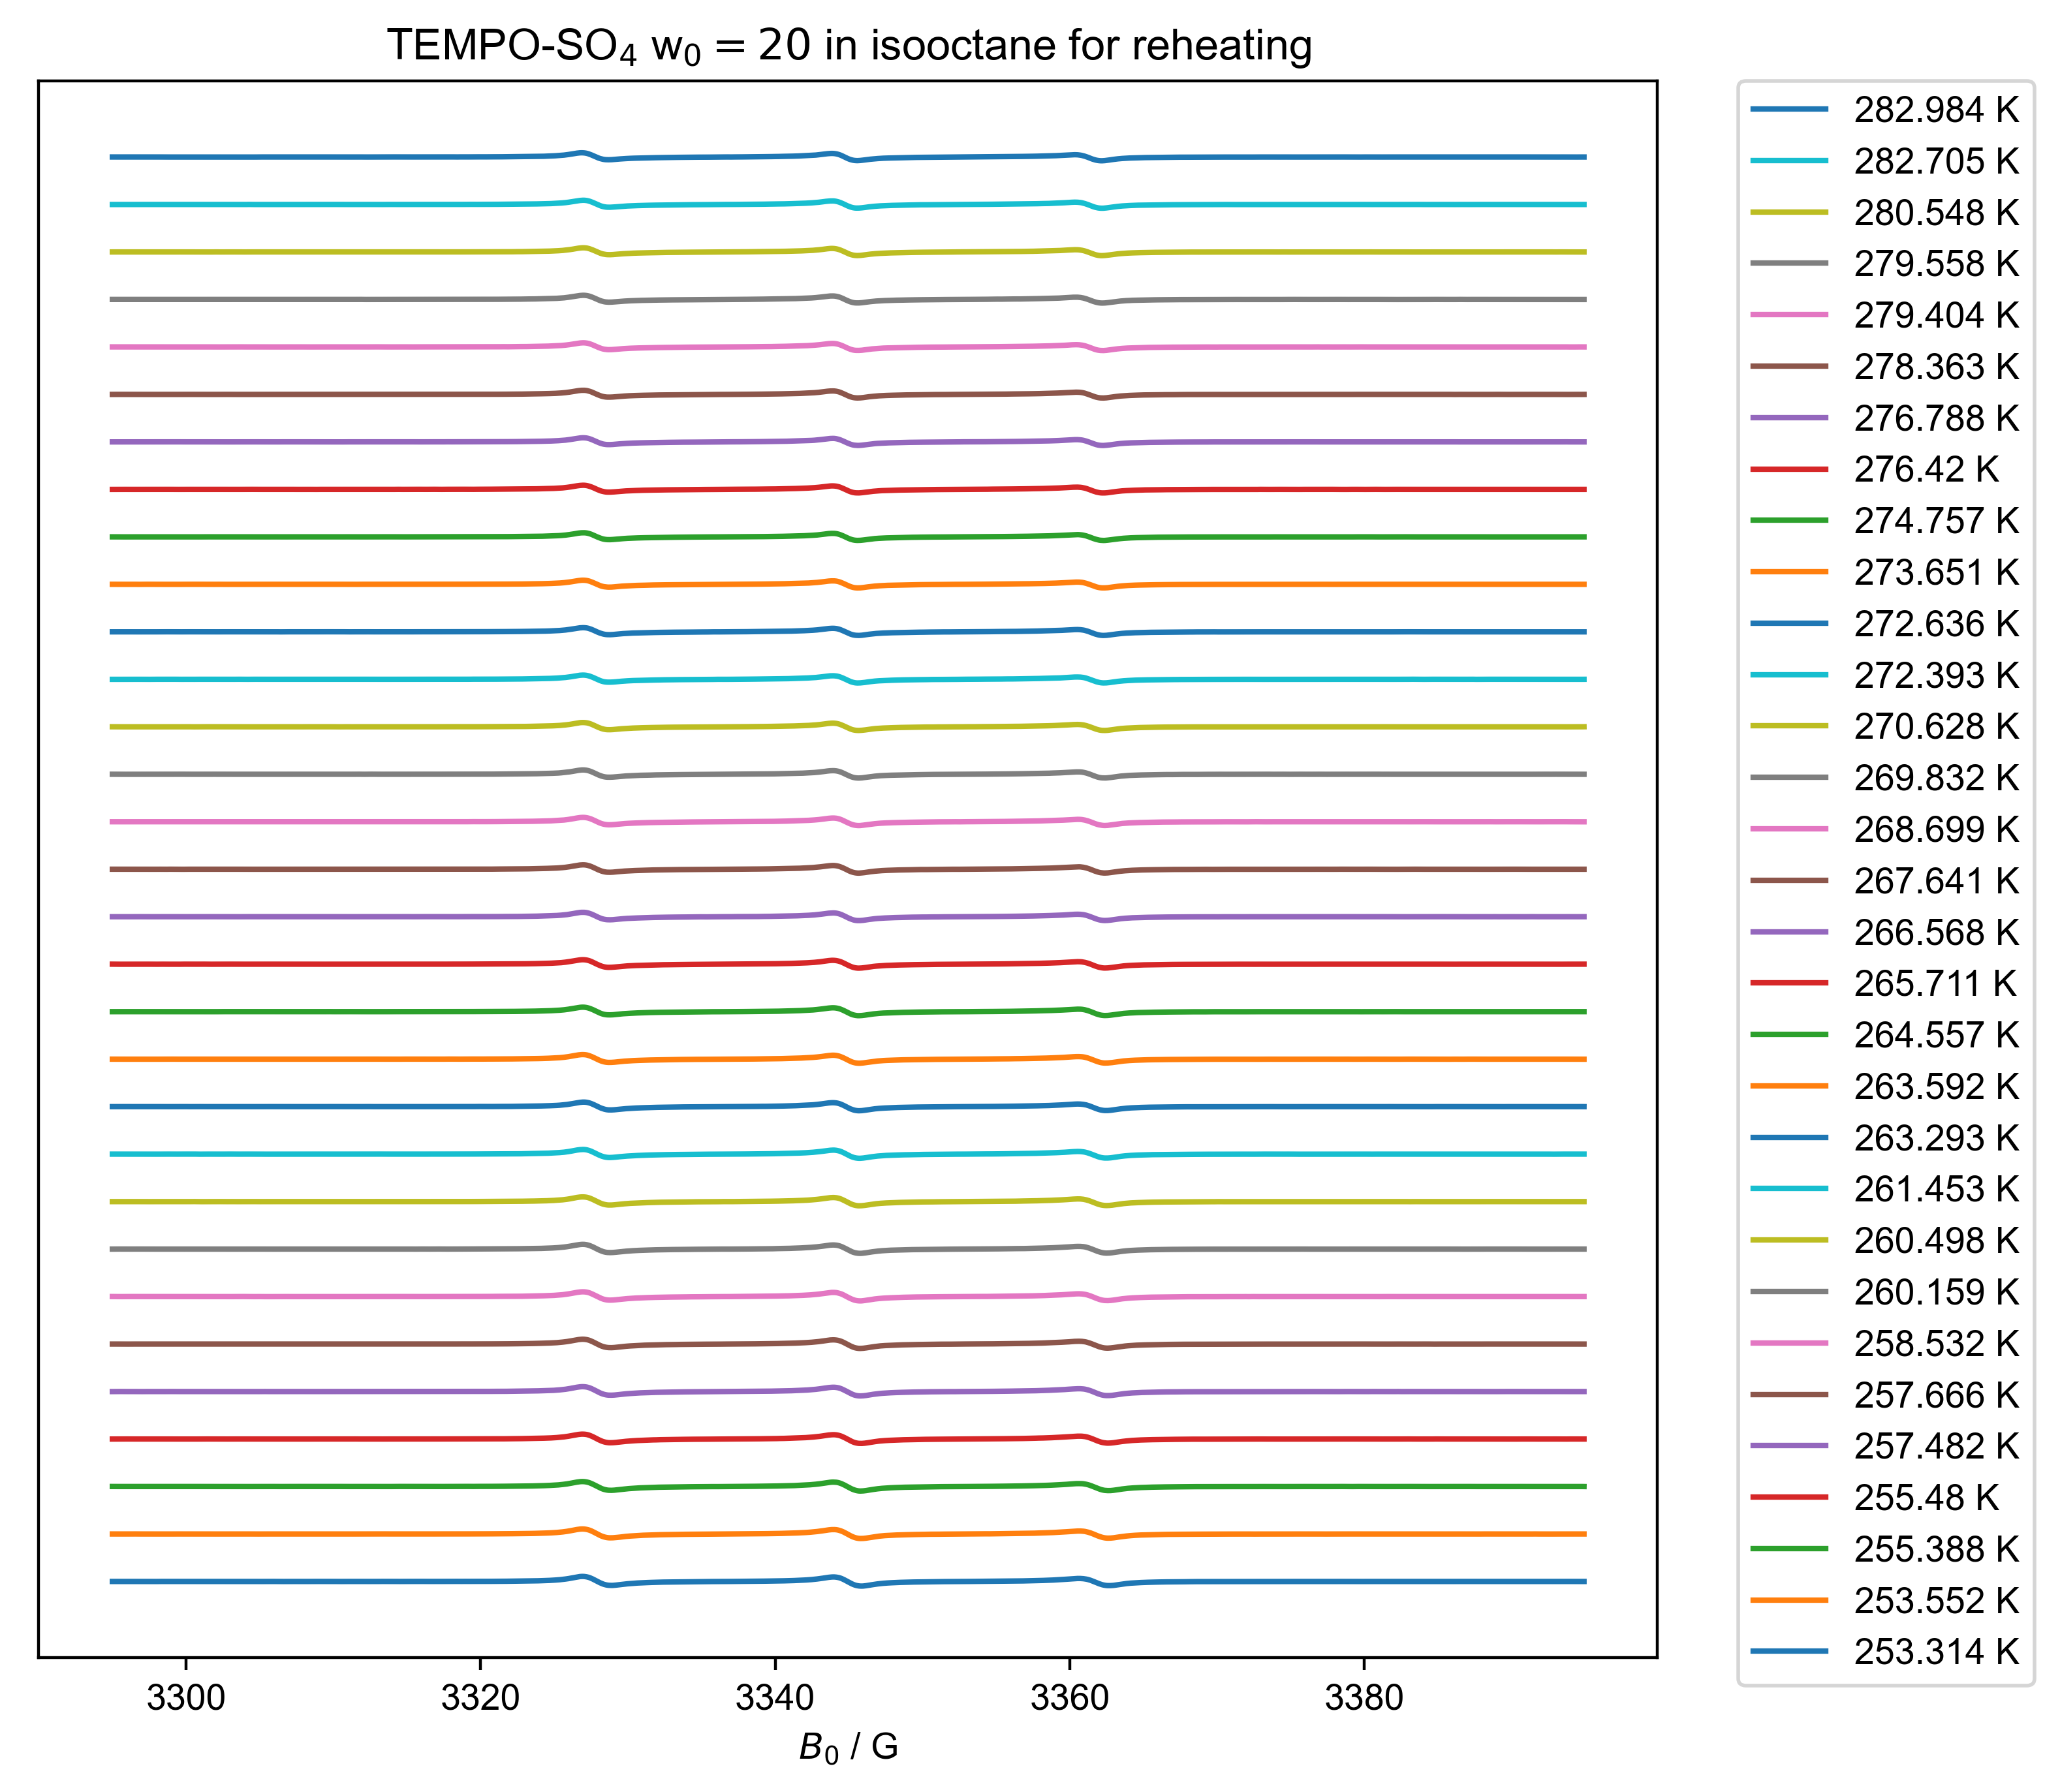

In [29]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0= 20$ in isooctane for reheating", (173, 373)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=400, figsize=(8,8)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += 20
#         offset += this_d2["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        # to get legend reversed
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

        
#     fancy_legend()

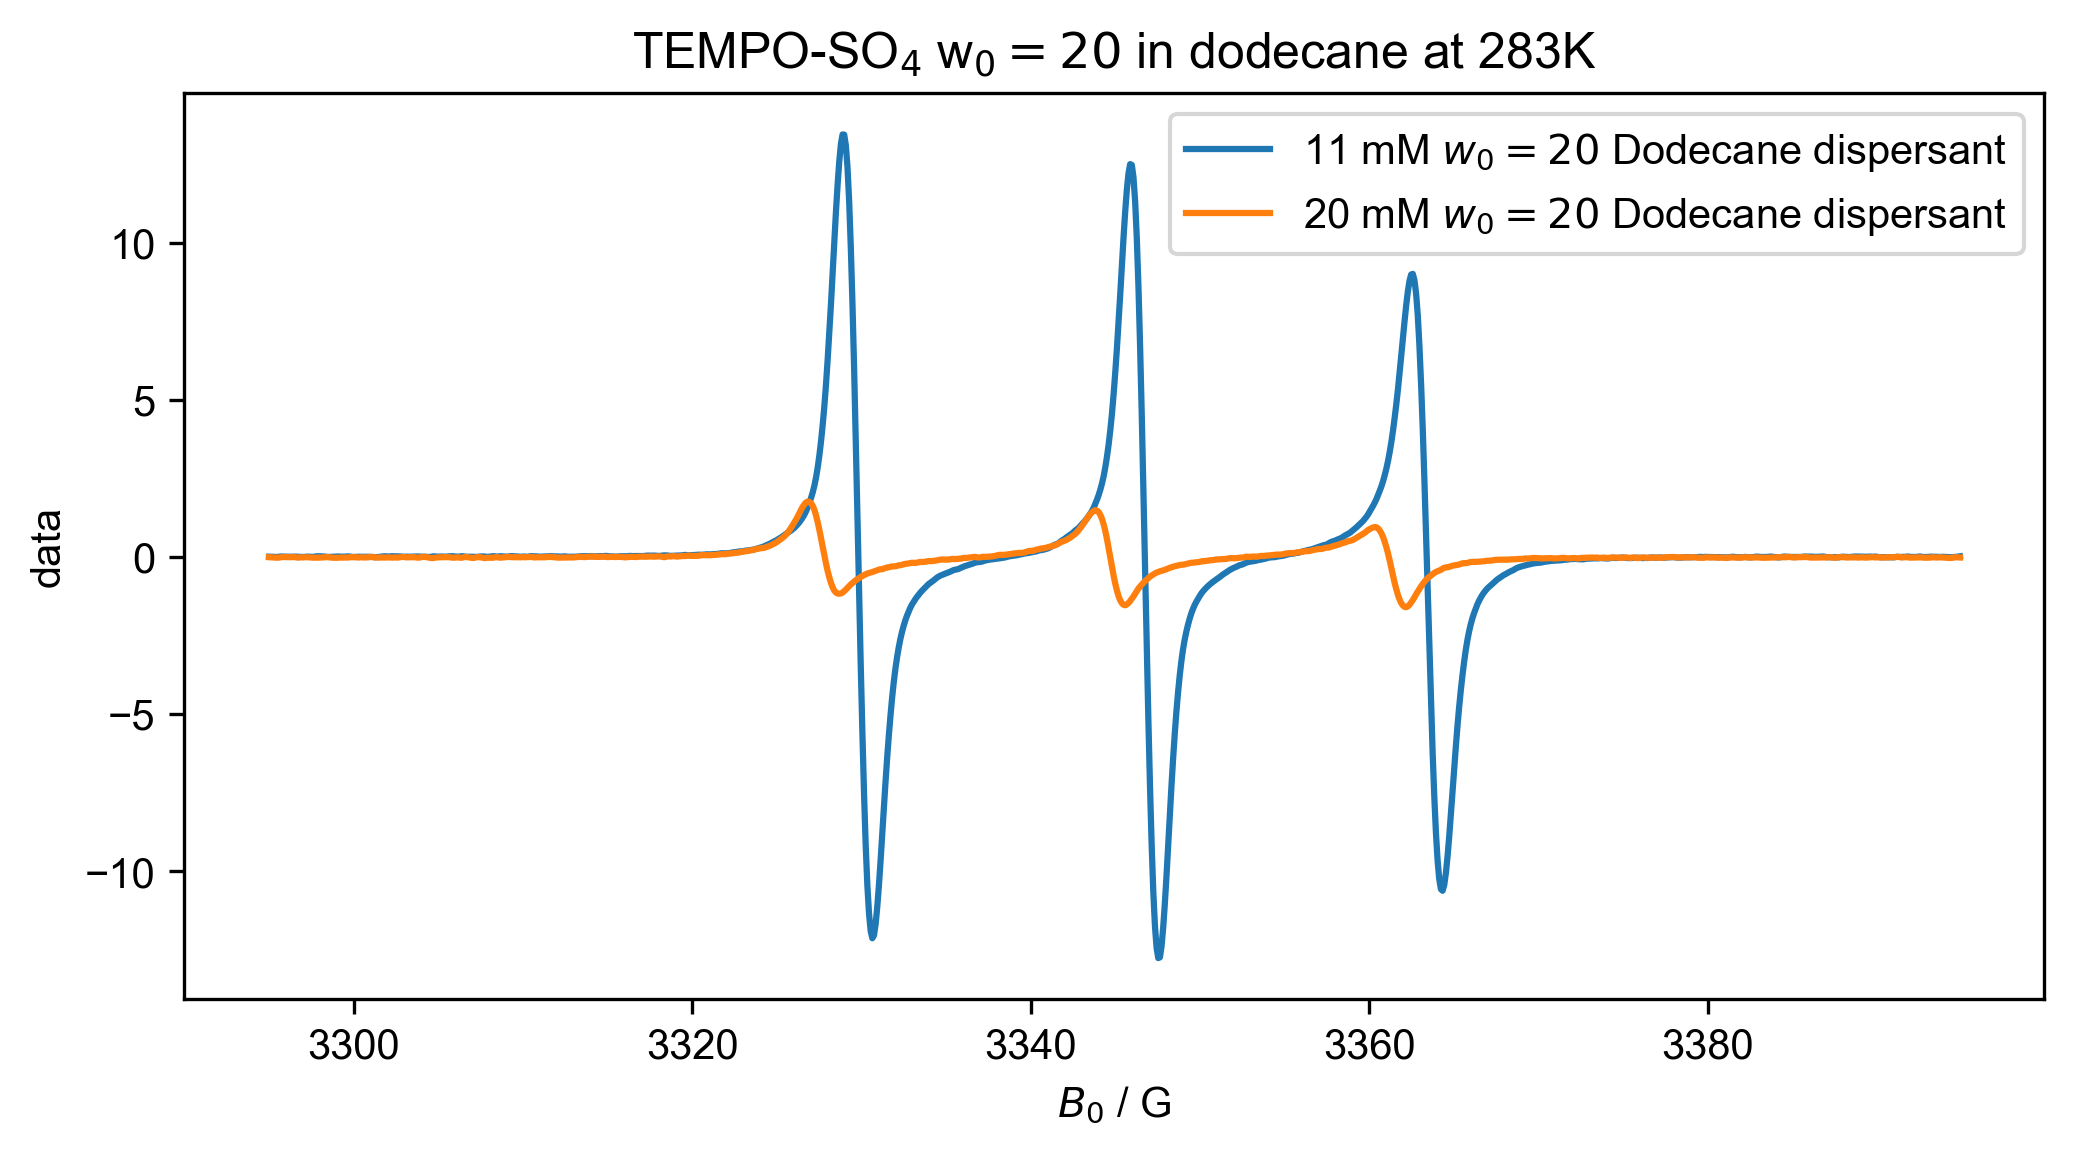

In [30]:
#near room temperature
#print(d1.getaxis("Temperature"))
figure(dpi=300, figsize=(8,4))
plot(d1["Temperature":283], label="11 mM $w_0= 20$ Dodecane dispersant")
plot(d2["Temperature":283], label="20 mM $w_0= 20$ Dodecane dispersant")
title("TEMPO-SO$_4$ w$_0= 20$ in dodecane at 283K")
legend()

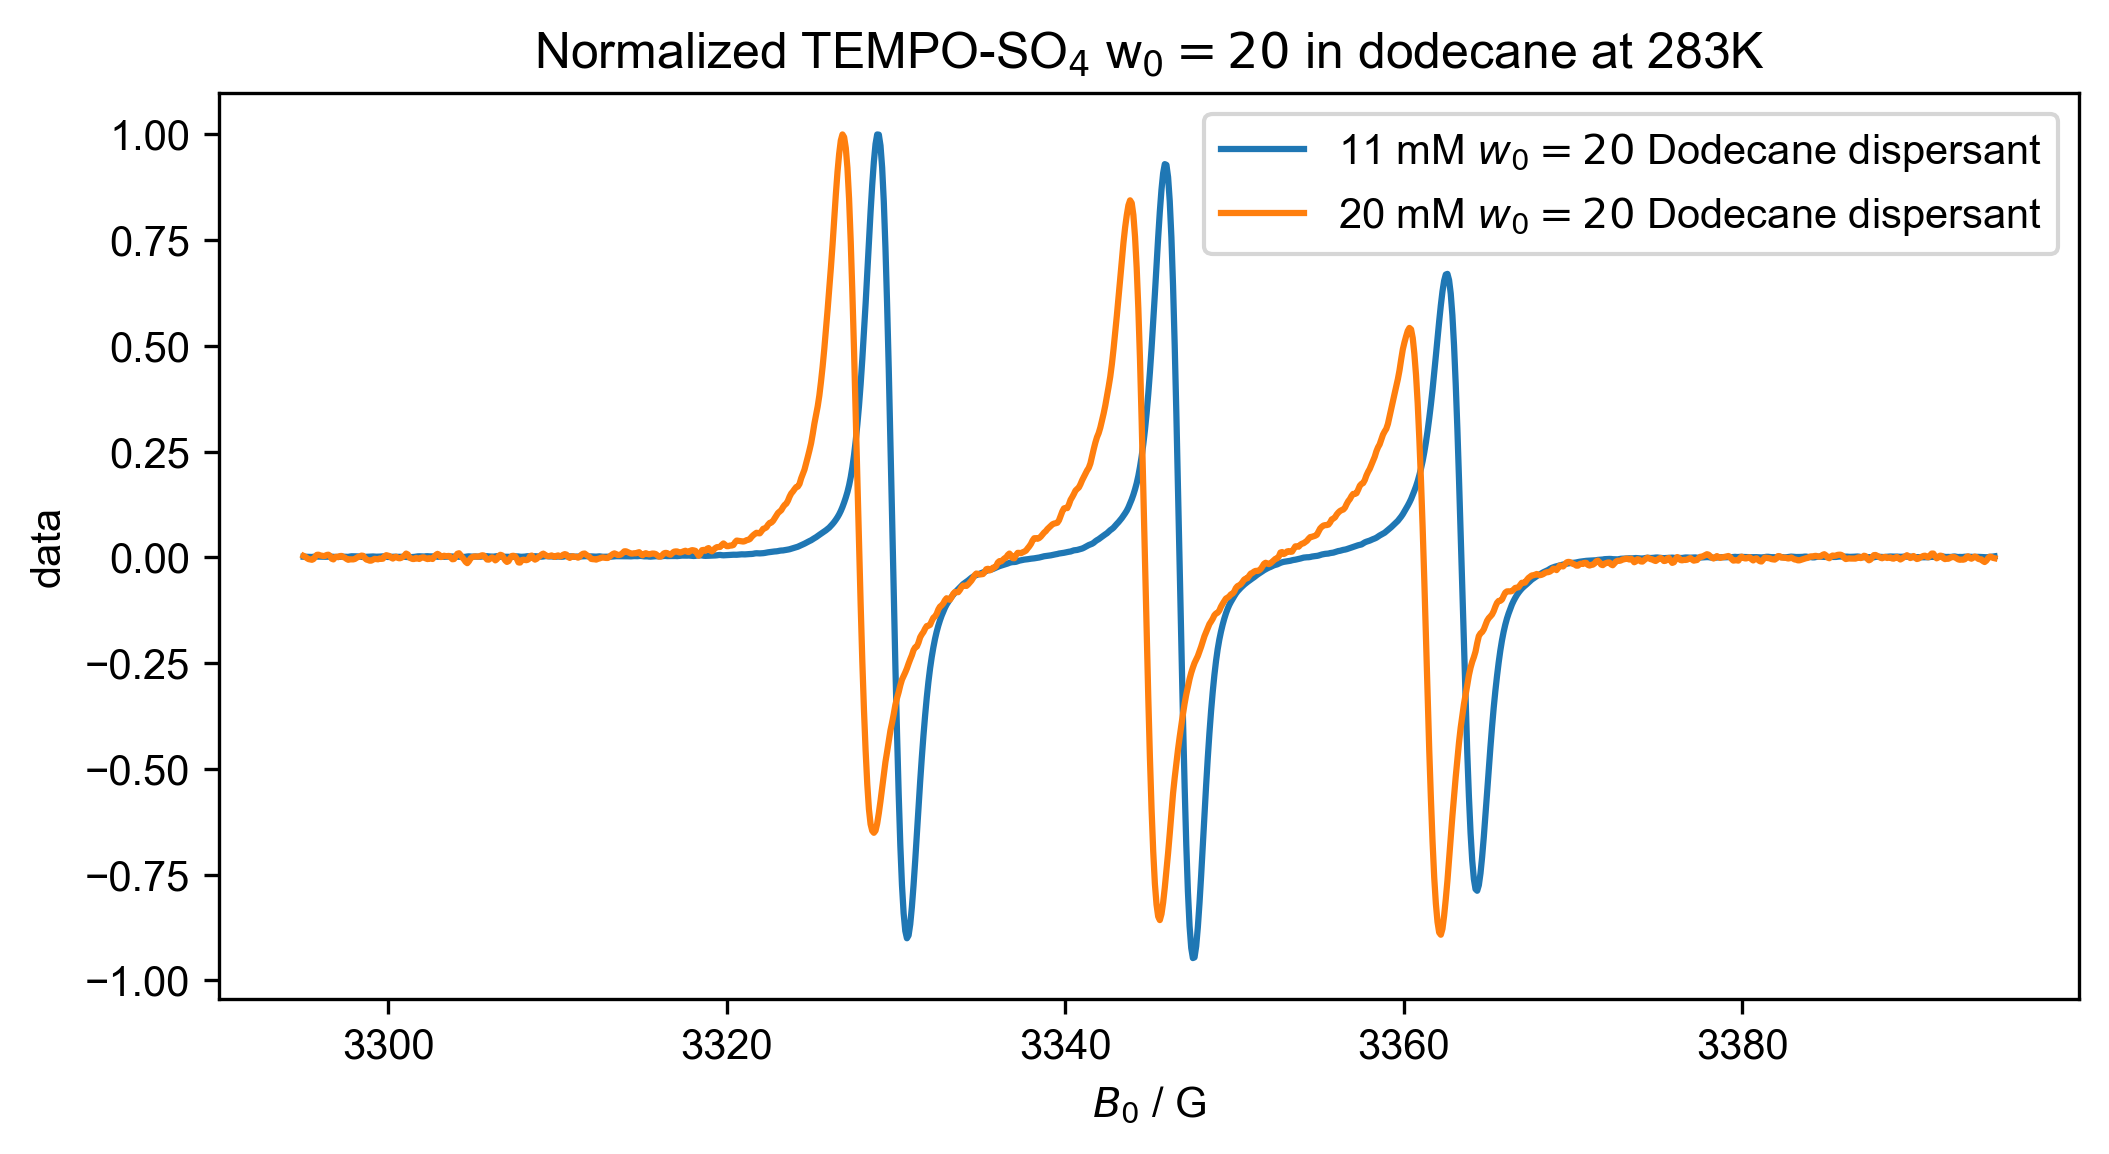

In [31]:
#Normalized
figure(dpi=300, figsize=(8,4))
plot(d1["Temperature": 283] / d1["Temperature": 283].max(), label="11 mM $w_0= 20$ Dodecane dispersant")
plot(d2["Temperature": 283] / d2["Temperature": 283].max(), label="20 mM $w_0= 20$ Dodecane dispersant")
title("Normalized TEMPO-SO$_4$ w$_0= 20$ in dodecane at 283K")
legend()